## GPT2 Architecture Part 3: GELU activation function

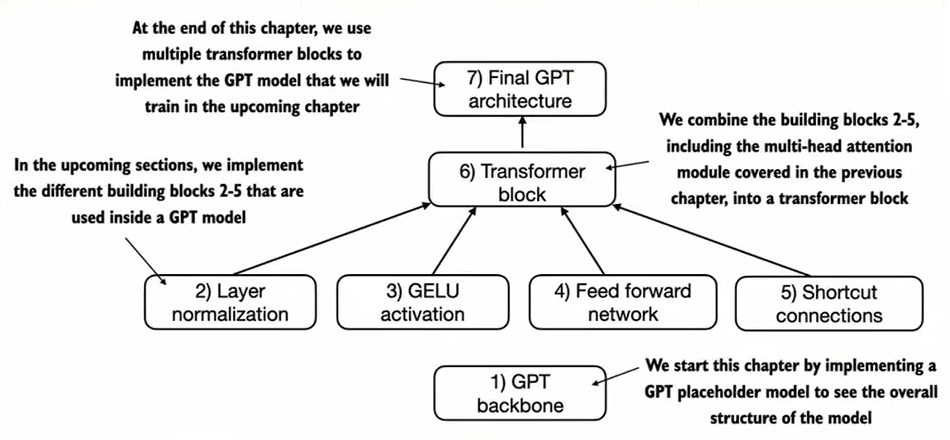

In [1]:
from IPython.display import Image
Image("images/stage_1_3_GELU/stages.png", width=800)

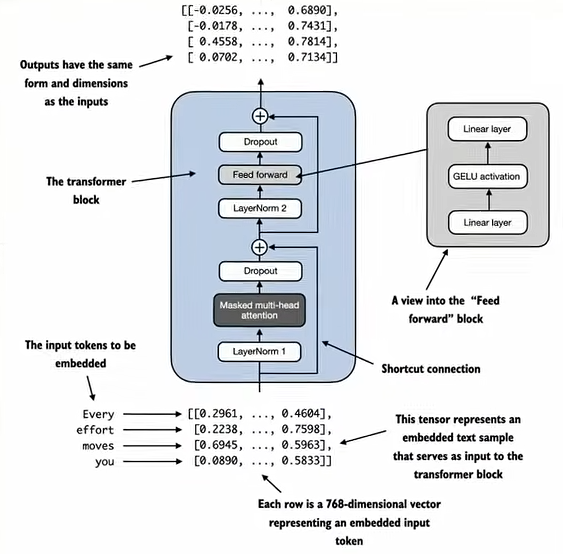

In [2]:
Image("images/stage_1_3_GELU/transformer_block.png", width=800)

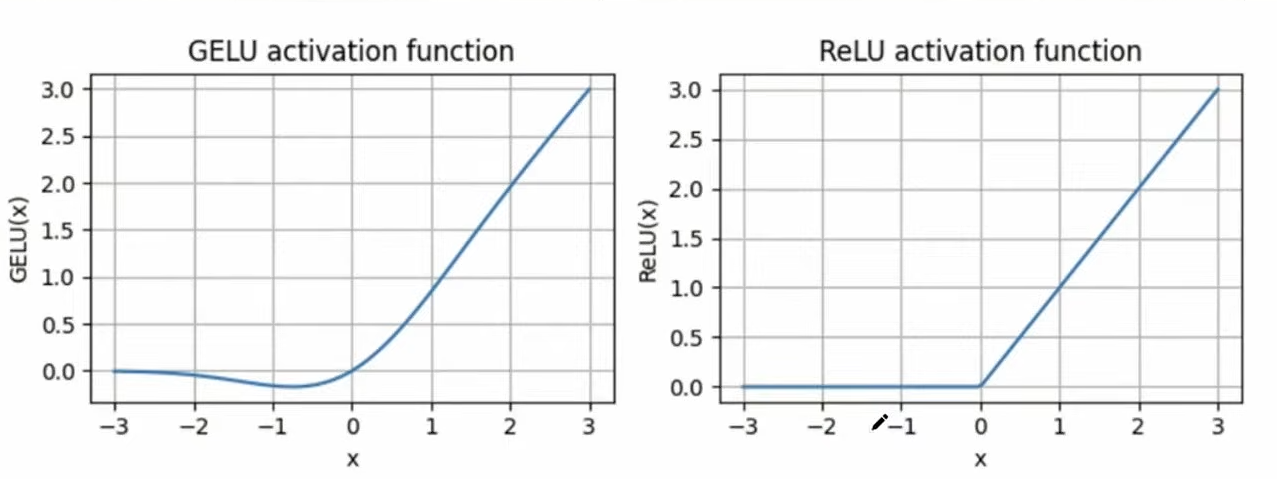

In [3]:

Image("images/stage_1_3_GELU/gelu_relu_comparison.png", width=800)

In [5]:
import torch
import torch.nn as nn
torch.set_printoptions(sci_mode=False)


In [6]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) * 
            (x + 0.044715 * torch.pow(x, 3))
            ))

#### Plot ReLU and GELU side by side for comparison

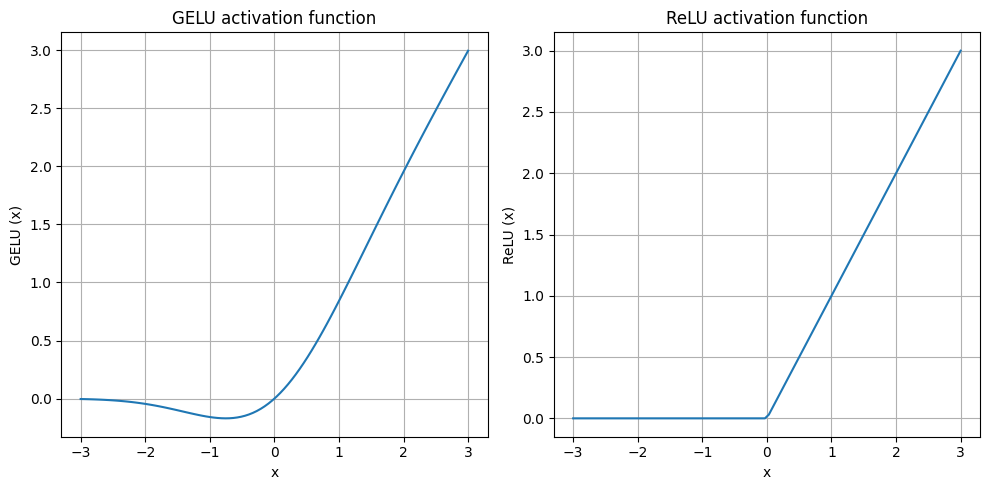

In [7]:
import matplotlib.pyplot as plt

# plot relu and gelu functions

gelu, relu = GELU(), nn.ReLU()

# some sample data
x = torch.linspace(-3, 3, 100)
y_gelu, y_relu = gelu(x), relu(x)

plt.figure(figsize=(10, 5))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ['GELU', 'ReLU']), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label} (x)")
    plt.grid()

plt.tight_layout()
plt.show()

- We can see ReLU is a piecewise linear function that outputs the input directly if it is positive, ZERO if negative 

- GELU is a smooth, nonlinear function that approximates ReLU but with a non-zero gradient for negative values

### Why GELU ?

- The smoothness of GELU, as shown in upper figure, can lead to a better optimization properties during training, as it allows for more nuanced adjustments to the model's parameter.

- In contrast, ReLU has sharp corner at zero, which can make optimizations harder, especially in networks that are very deep or have complex architectures.

- Moreover, unlike RELU which outputs ZERO for any negative input, GELU allows for a small, non-zero output for negative values

- This means that during the training process, neurons that receive negative input can still contribute to the learning process, albeit to a lesser extent than positive inputs. 

#### Feedforward layer - using GELU

- Let's use the GELU function to implement the small neural network module, FeedForward, that we will be using in the LLM's transformer block

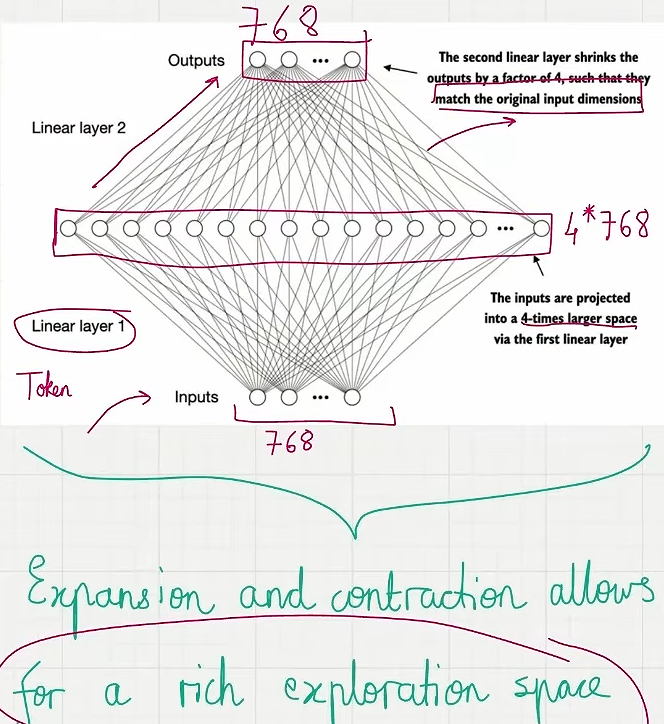

In [15]:
Image("images/stage_1_3_GELU/nn_layer_stacking.png", width=700)

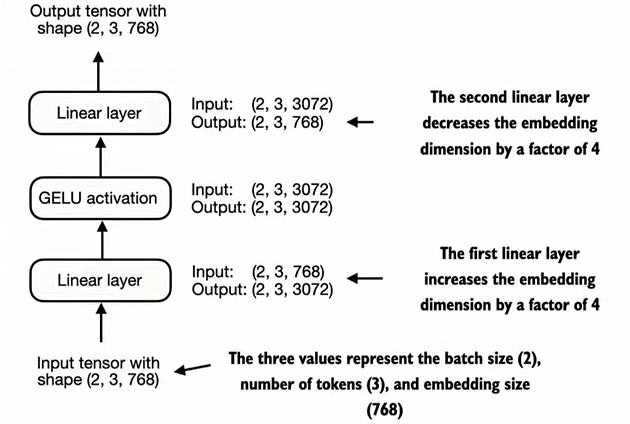

In [16]:
Image("images/stage_1_3_GELU/layer_inputs.png", width=700)

In [10]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,     # Vocabulary size of the model
    "context_length": 1024,  # Maximum context length for the model
    "emb_dim": 768,          # Embedding dimension of the model
    "n_heads": 12,           # Number of attention heads in the model
    "n_layers": 12,          # Number of transformer layers in the model
    "drop_rate": 0.1,        # Dropout rate for regularization
    "qkv_bias": True         # Whether to include bias terms in the query, key, and value projections
}

In [11]:
GPT_CONFIG_124M["emb_dim"]

768

In [12]:
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),  ## Expansion
            GELU(), ## Activation
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"])   ## Contraction
        )

    def forward(self, x):
        return self.layers(x)
    

- As we can see, FeedForward module is a small neural network consisting of 2 Linear Layers and a GELU activation function.

- In the 124 million parameter GPT model, it receives the input batches with tokens that have an embedding size of 768 each via GPT_CONFIG_124M dict with GPT_CONFIG_124["emb_dim"] = 768

In [13]:
ffn = FeedForward(GPT_CONFIG_124M)
x = torch.randn(2, 3, GPT_CONFIG_124M["emb_dim"])  # Example input tensor
out = ffn(x)
print("Input shape:", x.shape)
print("Output shape:", out.shape)

Input shape: torch.Size([2, 3, 768])
Output shape: torch.Size([2, 3, 768])


- The FeedForward module we implemneted in this section plays a crucial role in enhancing the model's ability to learn from and generalizes the data.

- Although the input and output dimensions are same, it internally expands the embedding dimension into a higher-dimensional space through the first linear layer

- This expansion is followed by a non-linear GELU activation, and then a contraction back to the original dimension with the second linear transformation.

- Such a design  allows for the exploration of a richer representation state.

#### How it helps:

The uniformity in inpt and output dimensions simplifies the architecture by enabling the stacking of multiple layers, without the need to adjust dimensions between them, thus making the model more scalable.

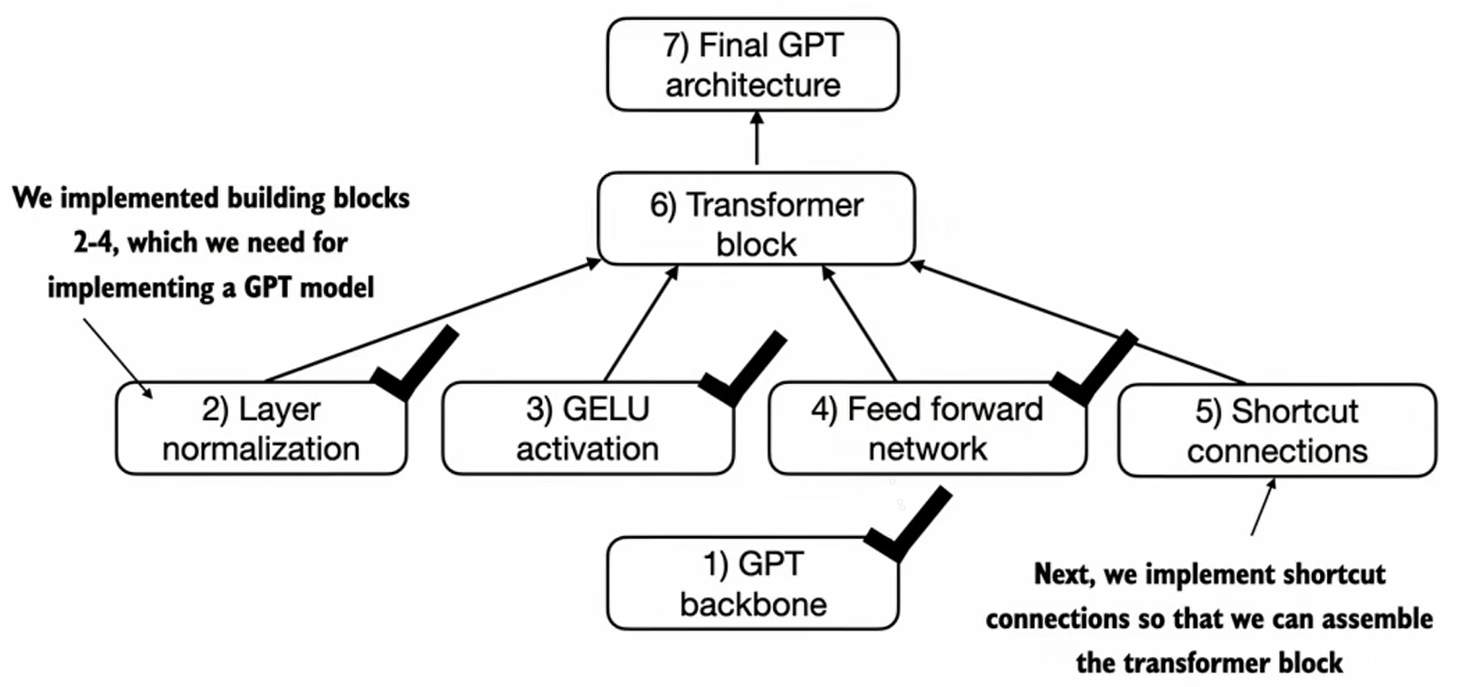

In [17]:
Image("images/stage_1_3_GELU/layer_progress.png", width=700)
